<a href="https://colab.research.google.com/github/zaidseliya0651-commits/231A050-NLP-Experiments/blob/main/Smart_Student_Feedback_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Smart Student Feedback Analyzer using NLP
### Experiment 1 – Mini Project

**Objective:** Analyze student feedback and classify it as **Positive, Neutral, or Negative** using NLP and Machine Learning.

**Dataset:** `student_feedback_dataset.csv`

**Algorithms/Techniques:** Text Preprocessing, TF-IDF, Logistic Regression

**Name:** Zaid Seliya
**UIN:** 231A050

In [ ]:
# STEP 1: Import Libraries

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

## STEP 2: Load Dataset from CSV

The project reads the student feedback from an external CSV file.  
This is better than keeping the dataset directly inside the Python code.

In [ ]:
# Upload CSV in Google Colab if it is not already present
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
file_name = "student_feedback_dataset.csv"
df = pd.read_csv(file_name)

print("CSV loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

In [ ]:
# STEP 3: Explore Dataset

print("Number of records:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Number of records: 180

Columns:
['feedback', 'sentiment']

Sentiment distribution:
sentiment
Positive    60
Neutral     60
Negative    60
Name: count, dtype: int64

Missing values:
feedback     0
sentiment    0
dtype: int64


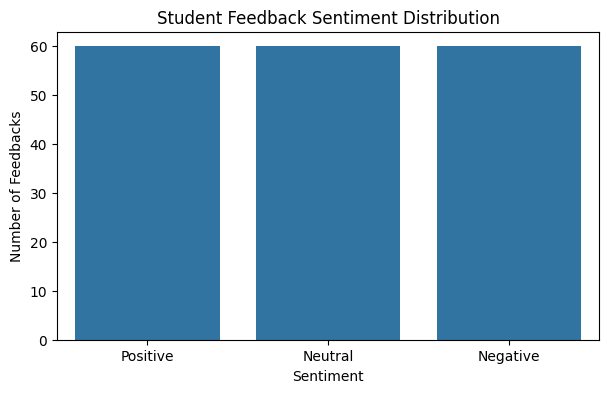

In [ ]:
# STEP 4: Visualize Sentiment Distribution

plt.figure(figsize=(7,4))
sns.countplot(data=df, x="sentiment")
plt.title("Student Feedback Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedbacks")
plt.show()

## STEP 5: Text Preprocessing

Steps:
1. Convert text to lowercase.
2. Remove special characters and numbers.
3. Remove extra spaces.

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_feedback"] = df["feedback"].apply(clean_text)

df[["feedback", "clean_feedback"]].head(10)

,feedback,clean_feedback
0,The teacher explained every topic clearly in s...,the teacher explained every topic clearly in s...
1,The teaching was okay during unit 1,the teaching was okay during unit
2,The explanation was not clear in this semester,the explanation was not clear in this semester
3,The lectures were excellent and easy to unders...,the lectures were excellent and easy to unders...
4,The lectures were average,the lectures were average
5,The lectures were boring and confusing,the lectures were boring and confusing
6,I really enjoyed the practical sessions,i really enjoyed the practical sessions
7,The course was manageable,the course was manageable
8,The practical sessions were not useful,the practical sessions were not useful
9,The professor was supportive and helpful in se...,the professor was supportive and helpful in se...


In [ ]:
# STEP 6: Split Dataset into Training and Testing Data

X = df["clean_feedback"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

## STEP 7: TF-IDF Feature Extraction

TF-IDF converts text into numerical features by giving importance to words/phrases that are useful for classification.

In [ ]:
if 'X_train' not in globals():
    print("X_train not found. Automatically running split from STEP 6...")
    from sklearn.model_selection import train_test_split
    X = df["clean_feedback"]
    y = df["sentiment"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=3000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF training matrix shape:", X_train_tfidf.shape)

TF-IDF training matrix shape: (144, 308)


## STEP 8: Train Logistic Regression Model

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 75.00%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.67      0.70        12
     Neutral       0.83      0.83      0.83        12
    Positive       0.69      0.75      0.72        12

    accuracy                           0.75        36
   macro avg       0.75      0.75      0.75        36
weighted avg       0.75      0.75      0.75        36



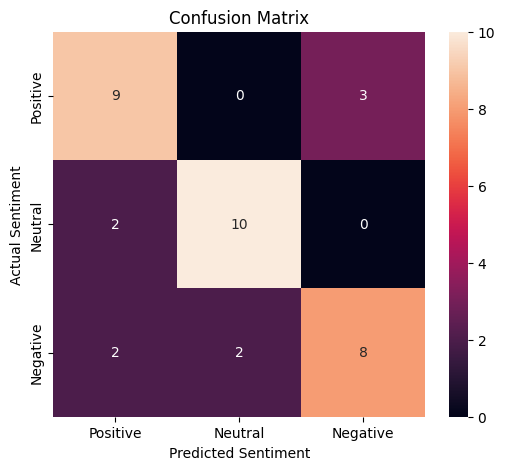

In [ ]:
# STEP 9: Confusion Matrix

labels = ["Positive", "Neutral", "Negative"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

## STEP 10: Predict New Student Feedback

In [19]:
def predict_sentiment(feedback):
    cleaned = clean_text(feedback)
    features = vectorizer.transform([cleaned])
    prediction = model.predict(features)[0]
    return prediction

test_feedbacks = [
    "The teacher explained everything very well",
    "The course was okay",
    "The lectures were confusing and boring",
    "The practical sessions were very helpful"
]

for text in test_feedbacks:
    print("Feedback:", text)
    print("Predicted Sentiment:", predict_sentiment(text))
    print("-" * 60)

Feedback: The teacher explained everything very well
Predicted Sentiment: Positive
------------------------------------------------------------
Feedback: The course was okay
Predicted Sentiment: Neutral
------------------------------------------------------------
Feedback: The lectures were confusing and boring
Predicted Sentiment: Negative
------------------------------------------------------------
Feedback: The practical sessions were very helpful
Predicted Sentiment: Negative
------------------------------------------------------------


In [26]:
#@title Enter Student Feedback and Run
user_feedback = "lecture are superb" #@param {type:"string"}

# Predict using our trained model
result = predict_sentiment(user_feedback)

print("Feedback:", user_feedback)
print("Predicted Sentiment:", result)

Feedback: lecture are superb
Predicted Sentiment: Positive


# Conclusion

The **Smart Student Feedback Analyzer** uses Natural Language Processing and Machine Learning to classify student feedback into Positive, Neutral, and Negative categories.

The system loads a larger dataset from an external CSV file, performs text preprocessing, extracts TF-IDF features, trains a Logistic Regression classifier, evaluates the model using accuracy and a confusion matrix, and predicts the sentiment of new feedback.

## Future Scope
- Use a real college/student feedback dataset with thousands of records.
- Support Hindi and Hinglish feedback.
- Compare Logistic Regression, Naive Bayes, SVM and deep-learning models.
- Create a Streamlit web application.
- Generate department-wise and subject-wise feedback reports.